# moonshot_ml_sandbox — Phase 3a: do the forecasts make better portfolios? (v2)

**Question (pre-registered).** If each month you had used the Phase 2 out-of-sample
predictions to decide what to hold, would the portfolio have been better or safer than
holding everything?

| Portfolio | Model used | Rule (rebuilt each month) |
|---|---|---|
| Baseline | none | hold every stock, equal weights |
| Pick outperformers | Outperform (M1) | hold the 20% with highest P(beat median) |
| Pick big winners | Top performer (M1) | hold the 20% with highest P(top 20%) |
| Avoid crashes | Crash (M1) | hold all except the 20% with highest P(crash) |
| Avoid wild movers | High vol (M2) | hold all except the 20% with highest P(top-20% vol) |

M2 is used only where it passed Phase 2's materiality rule (high vol).

**The concepts, in one line each**
- *Equal weight*: every held stock gets the same money. The portfolio return is the plain average of the stocks' returns.
- *Monthly rebalance*: on the first trading day of each month, read that day's predictions, choose the stocks, hold for the next 20 trading days (open t+1 → open t+21, the same window the models predicted).
- *CAGR*: the steady yearly growth rate that would turn ₹1 into the final wealth.
- *Volatility*: how much monthly results bounce around, scaled to a year.
- *Sharpe ratio*: average return per unit of volatility (no risk-free rate subtracted; fine for comparing portfolios with each other).
- *Max drawdown*: the deepest fall from a previous peak.
- *Turnover*: the fraction of the portfolio replaced each month (0 = unchanged, 1 = all new). A rough guide to trading cost, which this test ignores.
- *Paired block bootstrap*: resample the **same** months for portfolio and baseline, in runs of 6 consecutive months, 2,000 times. The spread of the differences is the confidence interval.

**Pre-committed reading rules**
1. *Avoid* portfolios **reduce risk** if the volatility-difference CI is below 0 and the max drawdown is smaller than baseline. The active-return CI says whether that cost or added return. They are **worth it** if the Sharpe-difference CI is above 0.
2. *Pick* portfolios **add return** if the active-return CI is above 0 and active return is positive in both halves (2014–19, 2020–25).

**Expectations (written before the run)** — Avoid portfolios: clearly lower volatility and drawdown; return similar or slightly better. Pick outperformers: small gain at best, mostly before 2020. Pick big winners: more volatile than baseline; possibly the worst risk-adjusted result.

**Known data gap (found in the first run, handled in Cells 5–6).** The V1 dataset has no cards from mid-March to mid-June 2025, although the source panel has data. Cell 5 measures the hole and tests its likely cause; Cell 6 makes the portfolios **sit out** the affected months (April, May, June 2025). A sat-out month counts as neither a gain nor a loss; CAGR is measured over invested months. Any *other* hole stops the notebook.

**How this notebook protects itself.** Every step prints what it did. Each `[PASS]` line is a check that would have raised an error if it failed. Cell 8 recomputes several results by an independent route (fresh model fit, raw prices, a different selection method) and compares them.

**Boundary** — a sandbox test without trading costs. A good result means "the forecasts carry decision value," not "this makes money."

## Cell 0 — Mount and locate inputs (read-only)

In [2]:
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive')
SANDBOX_DIR = Path("/content/drive/MyDrive/moonshot_ml_sandbox")
DATASET_PATH = sorted(SANDBOX_DIR.glob("ml_sandbox_v1_dataset_*.parquet"))[-1]
PANEL_PATH = sorted(Path("/content/drive/MyDrive/moonshot_compounding/features")
                    .glob("feature_panel_with_pit_v2_*.parquet"))[-1]
print("V1 dataset  :", DATASET_PATH.name, "\nsource panel:", PANEL_PATH.name)

Mounted at /content/drive
V1 dataset  : ml_sandbox_v1_dataset_2026-09-07.parquet 
source panel: feature_panel_with_pit_v2_2026-07-24.parquet


## Cell 1 — Logistic engine (identical to Phase 2, self-tested)

In [3]:
# ==============================================================================
# LOGISTIC-REGRESSION ENGINE  (identical code is self-tested on synthetic data)
# ==============================================================================
import warnings
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

EPS = 1e-12
RUNGS = ["M0", "M1", "M2"]          # M0 intercept only | M1 linear | M2 linear + squares


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def make_folds(dates, train_years=3, purge=21, max_test_year=None):
    # Rolling folds: train on `train_years` calendar years, test on the next one.
    # PURGE: drop the last `purge` trading dates before the train cutoff, so no
    # training card's 21-day forward window reaches into the test year.
    all_dates = np.array(sorted(pd.unique(dates)))
    first_year = pd.Timestamp(all_dates[0]).year
    last_date = pd.Timestamp(all_dates[-1])
    folds = []
    y0 = first_year
    while True:
        tr_lo = pd.Timestamp(f"{y0}-01-01")
        tr_hi = pd.Timestamp(f"{y0 + train_years - 1}-12-31")
        te_lo = pd.Timestamp(f"{y0 + train_years}-01-01")
        te_hi = pd.Timestamp(f"{y0 + train_years}-12-31")
        if te_lo > last_date or (max_test_year is not None and y0 + train_years > max_test_year):
            break
        hi_pos = np.searchsorted(all_dates, np.datetime64(tr_hi), side="right") - 1
        purge_from = pd.Timestamp(all_dates[hi_pos - purge + 1])
        folds.append(dict(test_year=y0 + train_years, train_lo=tr_lo,
                          purge_from=purge_from, train_hi=tr_hi,
                          test_lo=te_lo, test_hi=te_hi))
        y0 += 1
    return folds


def split_fold(frame, f):
    tr = frame[(frame["date"] >= f["train_lo"]) & (frame["date"] < f["purge_from"])]
    te = frame[(frame["date"] >= f["test_lo"]) & (frame["date"] <= f["test_hi"])]
    return tr, te


def design(frame, rung, feats):
    # M0: no features. M1: the z-scored features. M2: features + their squares.
    if rung == "M0":
        return np.zeros((len(frame), 0))
    X = frame[feats].to_numpy(dtype=float)
    if rung == "M2":
        X = np.column_stack([X, X ** 2])
    return X


def fit_logit(X, y):
    # Unregularized maximum-likelihood logistic regression.
    # Returns intercept b, weights w, and whether the optimizer converged.
    y = np.asarray(y, dtype=float)
    if X.shape[1] == 0:
        p = y.mean()
        return dict(b=float(np.log(p / (1 - p))), w=np.zeros(0), converged=True)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        try:
            m = LogisticRegression(penalty=None, solver="lbfgs", max_iter=5000)
            m.fit(X, y)
        except (ValueError, TypeError):   # older sklearn: no penalty=None
            m = LogisticRegression(C=1e10, solver="lbfgs", max_iter=5000)
            m.fit(X, y)
    conv = not any("converge" in str(c.message).lower() for c in caught)
    return dict(b=float(m.intercept_[0]), w=m.coef_[0].copy(), converged=conv)


def predict(model, X):
    return sigmoid(model["b"] + X @ model["w"])


def gradient_descent_logit(X, y, lr=2.0, n_iter=1500):
    # From-scratch fit: w <- w - lr * X^T (p - y) / n  (intercept as a column of 1s)
    Xa = np.column_stack([np.ones(len(X)), X])
    w = np.zeros(Xa.shape[1])
    hist = []
    for _ in range(n_iter):
        p = sigmoid(Xa @ w)
        hist.append(-np.mean(y * np.log(np.clip(p, EPS, 1)) +
                             (1 - y) * np.log(np.clip(1 - p, EPS, 1))))
        w -= lr * Xa.T @ (p - y) / len(y)
    return w, np.array(hist)


def logloss_vec(y, p):
    p = np.clip(p, EPS, 1 - EPS)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))


def daily_table(dates, y, preds):
    # Per-date sums of log-loss for each rung, and per-date AUC (rank formula).
    # AUC for one date = P(a random event stock outranks a random non-event stock).
    d = pd.DataFrame({"date": dates, "y": y})
    out = {}
    g = d.groupby("date")["y"]
    n = g.size()
    n1 = g.sum()
    n0 = n - n1
    out["n"] = n
    for r, p in preds.items():
        d["ll"] = logloss_vec(d["y"].to_numpy(), p)
        out[f"ll_{r}"] = d.groupby("date")["ll"].sum()
        d["rk"] = pd.Series(p, index=d.index).groupby(d["date"]).rank(method="average")
        sr = d.loc[d["y"] == 1].groupby("date")["rk"].sum().reindex(n.index).fillna(0.0)
        auc = (sr - n1 * (n1 + 1) / 2) / (n1 * n0)
        auc[(n1 == 0) | (n0 == 0)] = np.nan
        out[f"auc_{r}"] = auc
    return pd.DataFrame(out)


def summarize(daily, rung):
    skill = 1 - daily[f"ll_{rung}"].sum() / daily["ll_M0"].sum()
    return skill, daily[f"auc_{rung}"].mean()


def block_bootstrap(daily, B=1000, seed=0):
    # Resample whole calendar MONTHS with replacement (preserves within-month
    # dependence). Returns bootstrap draws of skill/AUC for M1, M2 and the
    # paired M2-minus-M1 skill gain.
    rng = np.random.default_rng(seed)
    month = daily.index.to_period("M")
    agg = pd.DataFrame({
        "ll0": daily["ll_M0"], "ll1": daily["ll_M1"], "ll2": daily["ll_M2"],
        "a1": daily["auc_M1"].fillna(0), "a2": daily["auc_M2"].fillna(0),
        "na": daily["auc_M1"].notna().astype(float),
    }).groupby(month).sum()
    A = agg.to_numpy()
    M = len(agg)
    idx = rng.integers(0, M, size=(B, M))
    C = np.zeros((B, M))
    for b in range(B):
        C[b] = np.bincount(idx[b], minlength=M)
    T = C @ A
    ll0, ll1, ll2, a1, a2, na = T.T
    s1, s2 = 1 - ll1 / ll0, 1 - ll2 / ll0
    return dict(skill_M1=s1, skill_M2=s2, gain=s2 - s1, auc_M1=a1 / na, auc_M2=a2 / na)


def calibration_bins(y, p, n_bins=10):
    b = pd.qcut(pd.Series(p), n_bins, labels=False, duplicates="drop")
    t = pd.DataFrame({"b": b.to_numpy(), "y": y, "p": p}).groupby("b")
    return t["p"].mean().to_numpy(), t["y"].mean().to_numpy(), t.size().to_numpy()


def run_event(frame, event_col, feats, folds, verbose=True):
    # Fit M0/M1/M2 on each fold's TRAIN, score on its TEST. Returns
    # pooled test predictions, per-date scores, per-fold weights, diagnostics.
    sub = frame[frame[event_col].notna()]
    rows, weights, diag = [], [], []
    for f in folds:
        tr, te = split_fold(sub, f)
        if len(tr) == 0 or len(te) == 0:
            continue
        ytr = tr[event_col].to_numpy(float)
        yte = te[event_col].to_numpy(float)
        pred = {}
        for r in RUNGS:
            m = fit_logit(design(tr, r, feats), ytr)
            pred[r] = predict(m, design(te, r, feats))
            weights.append(dict(test_year=f["test_year"], rung=r, b=m["b"],
                                **{f"w{i}": v for i, v in enumerate(m["w"])}))
            if r == "M0":
                diag.append(dict(test_year=f["test_year"], train_rate=ytr.mean(),
                                 test_rate=yte.mean(), b_M0=m["b"],
                                 logit_train_rate=np.log(ytr.mean() / (1 - ytr.mean()))))
            if not m["converged"]:
                print(f"  WARNING: {event_col} {r} fold {f['test_year']} did not converge")
        rows.append(pd.DataFrame({"date": te["date"].to_numpy(),
                                  "ticker": te["ticker"].to_numpy(),
                                  "test_year": f["test_year"], "y": yte,
                                  "p_M0": pred["M0"], "p_M1": pred["M1"], "p_M2": pred["M2"]}))
        if verbose:
            print(f"  {event_col}: fold {f['test_year']} fitted "
                  f"(train {len(tr):,} / test {len(te):,})")
    preds = pd.concat(rows, ignore_index=True)
    daily = daily_table(preds["date"].to_numpy(), preds["y"].to_numpy(),
                        {r: preds[f"p_{r}"].to_numpy() for r in RUNGS})
    daily["test_year"] = pd.Series(pd.to_datetime(daily.index).year, index=daily.index)
    return dict(preds=preds, daily=daily, weights=pd.DataFrame(weights),
                diag=pd.DataFrame(diag))

## Cell 2 — Portfolio engine (self-tested, including the gap-handling calendar)

In [4]:
# ==============================================================================
# PORTFOLIO ENGINE  (identical code is self-tested on synthetic data)
# ==============================================================================
import numpy as np
import pandas as pd

ANN = 12   # monthly rebalancing -> 12 periods per year

# Each portfolio: (prediction column, "top" = hold highest 20%, "drop" = hold all
# except highest 20%).  None = baseline (hold everything).
PORTFOLIOS = {
    "Baseline":           None,
    "Pick outperformers": ("p_outperform", "top"),
    "Pick big winners":   ("p_top", "top"),
    "Avoid crashes":      ("p_crash", "drop"),
    "Avoid wild movers":  ("p_highvol", "drop"),
}


def rebalance_dates(dates):
    # First available date of each calendar month (kept for reference; the
    # notebook uses plan_rebalances, which also checks for data gaps).
    s = pd.Series(pd.to_datetime(pd.unique(dates))).sort_values()
    return s.groupby(s.dt.to_period("M")).min().to_numpy()


def trading_calendar(dates, flags, min_names=30):
    # The market's trading days, taken from the SOURCE PANEL (not from V1), so a
    # hole in V1 shows up as "trading day with no cards" instead of vanishing.
    # A date counts if at least `min_names` stocks are in the index on it.
    d = pd.DataFrame({"date": pd.to_datetime(dates),
                      "in_index": (np.asarray(flags, dtype=float) == 1)})
    n = d.groupby("date")["in_index"].sum()
    return pd.DatetimeIndex(n.index[n >= min_names]).sort_values()


def plan_rebalances(calendar, card_dates, start, end, max_delay=3):
    # One row per calendar month in [start, end].
    #   first_trading_day : first trading day of the month (from the calendar)
    #   rebalance_date    : first trading day of the month that HAS cards
    #   delay             : trading days between the two (0 = normal)
    #   invest            : True if cards exist and delay <= max_delay
    # A month whose cards start late is SKIPPED, never shifted: shifting would make
    # its 20-day holding overlap the next month's.
    cal = pd.DatetimeIndex(pd.to_datetime(calendar)).unique().sort_values()
    has_cards = cal.isin(pd.DatetimeIndex(pd.to_datetime(pd.unique(card_dates))))
    pos = np.arange(len(cal))
    month = cal.to_period("M")
    rows = []
    for m in pd.period_range(start, end, freq="M"):
        in_m = np.asarray(month == m)
        if not in_m.any():
            rows.append(dict(month=str(m), first_trading_day=pd.NaT, rebalance_date=pd.NaT,
                             delay=np.nan, invest=False, status="no trading days in calendar"))
            continue
        first_pos = pos[in_m][0]
        card_pos = pos[in_m & has_cards]
        if len(card_pos) == 0:
            rows.append(dict(month=str(m), first_trading_day=cal[first_pos], rebalance_date=pd.NaT,
                             delay=np.nan, invest=False, status="no cards this month -> sit out"))
            continue
        delay = int(card_pos[0] - first_pos)
        invest = delay <= max_delay
        status = "ok" if delay == 0 else f"cards start {delay} trading day(s) late"
        if not invest:
            status += f" (> {max_delay}) -> sit out"
        rows.append(dict(month=str(m), first_trading_day=cal[first_pos],
                         rebalance_date=cal[card_pos[0]] if invest else pd.NaT,
                         delay=delay, invest=invest, status=status))
    return pd.DataFrame(rows)


def holding_gaps(calendar, reb_dates, hold=20):
    # For consecutive rebalances t and t' (gap = trading days between them):
    # holding t runs open[t+1] -> open[t+1+hold]; the next starts at open[t'+1].
    #   overlap = days both are held = max(0, hold - gap)
    #   uncovered = days neither is held = max(0, gap - hold)
    # Pairs that are not consecutive calendar months (a sit-out in between) are
    # flagged and excluded from the overlap statistics.
    cal = pd.DatetimeIndex(pd.to_datetime(calendar)).unique().sort_values()
    reb = pd.DatetimeIndex(pd.to_datetime(reb_dates)).sort_values()
    p = cal.get_indexer(reb)
    if (p < 0).any():
        raise ValueError(f"rebalance dates not in calendar: {list(reb[p < 0])}")
    month_no = np.asarray(reb.year * 12 + reb.month)           # months since year 0
    out = pd.DataFrame({"from": reb[:-1], "to": reb[1:], "gap": np.diff(p),
                        "adjacent_months": np.diff(month_no) == 1})
    out["overlap"] = np.maximum(0, hold - out["gap"])
    out["uncovered"] = np.maximum(0, out["gap"] - hold)
    return out


def select(day, rule, frac=0.20):
    # Boolean mask of the stocks held on one rebalance date.
    if rule is None:
        return np.ones(len(day), dtype=bool)
    col, kind = rule
    n = len(day)
    k = int(round(frac * n))                       # exact count flagged
    order = day[col].rank(method="first").to_numpy()   # 1 = lowest prediction
    flagged = order > n - k                        # the k highest predictions
    return flagged if kind == "top" else ~flagged


def build(snap, portfolios=PORTFOLIOS, frac=0.20):
    # snap: one row per (rebalance date, stock) with 'ret' and prediction columns.
    # Returns monthly portfolio returns, holdings, and held/dropped diagnostics.
    rets, holds, diag = {p: {} for p in portfolios}, {p: {} for p in portfolios}, []
    for d, day in snap.groupby("date", sort=True):
        day = day.reset_index(drop=True)
        for p, rule in portfolios.items():
            m = select(day, rule, frac)
            rets[p][d] = day.loc[m, "ret"].mean()
            holds[p][d] = frozenset(day.loc[m, "ticker"])
            if rule is not None and "ev_crash" in day:
                diag.append(dict(date=d, portfolio=p, n_held=int(m.sum()),
                                 n_other=int((~m).sum()),
                                 ret_held=day.loc[m, "ret"].mean(),
                                 ret_other=day.loc[~m, "ret"].mean(),
                                 crash_held=day.loc[m, "ev_crash"].mean(),
                                 crash_other=day.loc[~m, "ev_crash"].mean()))
    R = pd.DataFrame(rets).sort_index()
    return R, holds, pd.DataFrame(diag)


def turnover(hold_by_date):
    # One-way turnover between consecutive equal-weight portfolios:
    # 0.5 * sum |w_t - w_{t-1}|.  0 = unchanged, 1 = completely replaced.
    ds = sorted(hold_by_date)
    out = []
    for a, b in zip(ds[:-1], ds[1:]):
        A, Bh = hold_by_date[a], hold_by_date[b]
        wa, wb = 1 / len(A), 1 / len(Bh)
        tot = sum(abs((wb if s in Bh else 0) - (wa if s in A else 0)) for s in A | Bh)
        out.append(0.5 * tot)
    return float(np.mean(out)) if out else np.nan


def wealth_curve(r):
    return np.concatenate([[1.0], np.cumprod(1 + np.asarray(r, float))])


def max_drawdown(r):
    w = wealth_curve(r)
    return float((w / np.maximum.accumulate(w) - 1).min())


def perf(r):
    r = np.asarray(r, float)
    n = len(r)
    return dict(cagr=wealth_curve(r)[-1] ** (ANN / n) - 1,
                vol=r.std(ddof=1) * np.sqrt(ANN),
                sharpe=r.mean() / r.std(ddof=1) * np.sqrt(ANN),
                max_dd=max_drawdown(r),
                hit_months=float(np.mean(r > 0)))


def block_indices(n, block, rng):
    # Indices for one moving-block bootstrap sample of length n.
    starts = rng.integers(0, n - block + 1, size=int(np.ceil(n / block)))
    return np.concatenate([np.arange(s, s + block) for s in starts])[:n]


def paired_bootstrap(rp, rb, B=2000, block=6, seed=0):
    # Resample the SAME months for portfolio and baseline (paired), in blocks of
    # `block` consecutive months to keep short-run dependence. Returns draws of:
    # annualised active return, volatility difference, Sharpe difference.
    rp, rb = np.asarray(rp, float), np.asarray(rb, float)
    rng = np.random.default_rng(seed)
    out = np.empty((B, 3))
    for b in range(B):
        i = block_indices(len(rp), block, rng)
        p, q = rp[i], rb[i]
        out[b] = [(p - q).mean() * ANN,
                  (p.std(ddof=1) - q.std(ddof=1)) * np.sqrt(ANN),
                  (p.mean() / p.std(ddof=1) - q.mean() / q.std(ddof=1)) * np.sqrt(ANN)]
    return dict(active=out[:, 0], vol_diff=out[:, 1], sharpe_diff=out[:, 2])

## Cell 3 — Rebuild the four events exactly as in Phase 2

In [5]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
from datetime import date
df = pd.read_parquet(DATASET_PATH); df["date"] = pd.to_datetime(df["date"])
RAW = ["momentum_12_1","reversal_1m","realized_vol_60","log_turnover","overnight_drift"]
Z = [f + "_z" for f in RAW]
panel = pd.read_parquet(PANEL_PATH, columns=["Date","ticker","Open","Close","daily_return","in_nifty500_flag"])
panel["Date"] = pd.to_datetime(panel["Date"]).dt.tz_localize(None)
panel = panel.sort_values(["ticker","Date"]).reset_index(drop=True)
panel["fwd_vol"] = (panel.groupby("ticker")["daily_return"]
                    .transform(lambda s: s.rolling(20, min_periods=10).std().shift(-20)))
df = df.merge(panel[["Date","ticker","fwd_vol"]], left_on=["date","ticker"],
              right_on=["Date","ticker"], how="left").drop(columns=["Date"])
df = df.sort_values(["date","ticker"]).reset_index(drop=True)
pct = lambda c: df.groupby("date")[c].rank(pct=True)
r = pct("fwd_ret_20d")
df["ev_outperform"] = (r > 0.5).astype(float)
df["ev_top"] = (r > 0.8).astype(float)
df["ev_crash"] = (r <= 0.2).astype(float)
df["ev_highvol"] = np.where(df["fwd_vol"].notna(), (pct("fwd_vol") > 0.8).astype(float), np.nan)
EVENTS = ["ev_outperform","ev_top","ev_crash","ev_highvol"]
for e in EVENTS: print(f"  {e:<14} rate {df[e].mean():.4f}")

  ev_outperform  rate 0.5006
  ev_top         rate 0.2009
  ev_crash       rate 0.1993
  ev_highvol     rate 0.2009


## Cell 4 — Out-of-sample predictions (re-fitted, then checked against Phase 2)

Same engine, same data, same folds → the predictions must reproduce Phase 2's skill scores.
That check (below) is the proof that these are the same out-of-sample forecasts.
They are saved once to Drive so later phases can reuse them; if a saved file already exists it is loaded, never overwritten.

In [6]:
PRED_PATH = SANDBOX_DIR / f"phase2_oos_predictions_{date.today().isoformat()}.parquet"
existing = sorted(SANDBOX_DIR.glob("phase2_oos_predictions_*.parquet"))
folds = make_folds(df["date"], max_test_year=2025)
if existing:
    preds = pd.read_parquet(existing[-1]); print("loaded cached predictions:", existing[-1].name)
else:
    t0 = time.time(); parts = []
    for e in EVENTS:
        out = run_event(df, e, Z, folds, verbose=False)
        parts.append(out["preds"].assign(event=e)); print(f"  fitted {e}")
    preds = pd.concat(parts, ignore_index=True)
    assert not PRED_PATH.exists()
    preds.to_parquet(PRED_PATH, index=False)
    print(f"fitted and saved {PRED_PATH.name} in {(time.time()-t0)/60:.1f} min")
preds["date"] = pd.to_datetime(preds["date"])

# TRIPWIRE: reproduce Phase 2 skill (values from the Phase 2 run)
PHASE2 = {("ev_outperform","M1"):0.0027, ("ev_top","M1"):0.0022, ("ev_crash","M1"):0.0192,
          ("ev_highvol","M1"):0.1292, ("ev_highvol","M2"):0.1435}
print("\nreproduction check (skill vs Phase 2):")
for (e, rg), ref in PHASE2.items():
    p = preds[preds.event == e]
    dl = daily_table(p["date"].to_numpy(), p["y"].to_numpy(), {r: p[f"p_{r}"].to_numpy() for r in RUNGS})
    s = summarize(dl, rg)[0]
    print(f"  {e:<14} {rg}: {s:.4f}  (Phase 2: {ref:.4f})")
    assert abs(s - ref) < 6e-4, "predictions do not reproduce Phase 2 — stop"
print("[PASS] predictions reproduce Phase 2")

loaded cached predictions: phase2_oos_predictions_2026-10-03.parquet

reproduction check (skill vs Phase 2):
  ev_outperform  M1: 0.0027  (Phase 2: 0.0027)
  ev_top         M1: 0.0022  (Phase 2: 0.0022)
  ev_crash       M1: 0.0192  (Phase 2: 0.0192)
  ev_highvol     M1: 0.1292  (Phase 2: 0.1292)
  ev_highvol     M2: 0.1435  (Phase 2: 0.1435)
[PASS] predictions reproduce Phase 2


## Cell 5 — Data-gap audit: where is V1 missing days, and why?

**A.** Build the market's trading calendar from the *source panel* (days with ≥30 in-index
stocks). Every trading day inside V1's date span that has no V1 cards is listed, grouped
into runs of consecutive days. Short runs next to the vendor-failure date are expected
(a card whose buy or sell day is 2025-03-18 has no defined return). Exactly **one long run**
(≥5 days) is expected, containing 2025-03-18. Anything else stops the notebook.

**B.** Test the suspected cause. The V1 builder reads `realized_vol_60` straight from the
panel and drops any card with a missing feature. If the panel's 60-day volatility needs all
60 daily returns, one missing return on 2025-03-18 blanks it for ~60 trading days. Below:
the share of in-index stocks with a missing value, for each column the builder uses,
before / inside / after the hole. This part is diagnostic only. It does not change the
portfolios, and it never stops the run.

In [7]:
import pyarrow.parquet as pq
VENDOR_FAIL = pd.Timestamp("2025-03-18")

# ---- A. trading days with no V1 cards --------------------------------------
CAL = trading_calendar(panel["Date"], panel["in_nifty500_flag"], min_names=30)
v1_days = pd.DatetimeIndex(df["date"].unique()).sort_values()
print(f"market calendar (panel, >=30 in-index names): {len(CAL):,} trading days, "
      f"{CAL[0].date()} -> {CAL[-1].date()}")
print(f"V1 card dates                                : {len(v1_days):,} days, "
      f"{v1_days[0].date()} -> {v1_days[-1].date()}")
print(f"vendor-failure date {VENDOR_FAIL.date()} in market calendar: {VENDOR_FAIL in CAL}")
outside = v1_days.difference(CAL)
assert len(outside) == 0, f"V1 has card dates that are not market trading days: {list(outside[:5])}"
print("[PASS] every V1 card date is a market trading day")

span = CAL[(CAL >= v1_days[0]) & (CAL <= v1_days[-1])]
no_cards = span[~span.isin(v1_days)]
pos_nc = span.get_indexer(no_cards)
run_id = np.concatenate([[0], np.cumsum(np.diff(pos_nc) != 1)]) if len(pos_nc) else np.array([], int)
RUNS = (pd.DataFrame({"day": no_cards, "run": run_id}).groupby("run")["day"]
        .agg(first="min", last="max", trading_days="size").reset_index(drop=True))
# Days whose buy (t+1) or sell (t+21) open falls on the vendor date: return undefined by design.
if VENDOR_FAIL in CAL:
    vpos = CAL.get_loc(VENDOR_FAIL)
    by_design = {CAL[vpos - 1], CAL[vpos - 21], VENDOR_FAIL}
else:
    by_design = set()
def reason(row):
    days = set(span[(span >= row["first"]) & (span <= row["last"])])
    if row["first"] <= VENDOR_FAIL <= row["last"] and row["trading_days"] >= 5:
        return "THE 2025 HOLE"
    if days <= by_design:
        return "vendor date is buy/sell day (by design)"
    return "UNEXPLAINED"
RUNS["reason"] = RUNS.apply(reason, axis=1) if len(RUNS) else []
print(f"\ntrading days inside V1's span with NO cards: {len(no_cards)}, in {len(RUNS)} run(s):")
print(RUNS.assign(first=RUNS["first"].dt.date, last=RUNS["last"].dt.date).to_string(index=False))
LONG = RUNS[RUNS["trading_days"] >= 5]
assert len(LONG) == 1 and LONG.iloc[0]["reason"] == "THE 2025 HOLE", \
    "expected exactly one long gap, containing the vendor-failure date — see table above"
HOLE_LO, HOLE_HI = LONG.iloc[0]["first"], LONG.iloc[0]["last"]
HOLE_DAYS = int(LONG.iloc[0]["trading_days"])
print(f"[PASS] exactly one long gap: {HOLE_LO.date()} -> {HOLE_HI.date()} = {HOLE_DAYS} trading days")
n_unexpl = int((RUNS["reason"] == "UNEXPLAINED").sum()) if len(RUNS) else 0
print(f"short unexplained runs: {n_unexpl}  (listed above; they matter only if they hit a "
      "month's first trading day, which Cell 6 checks)")

# ---- B. which builder input is blank during the hole? ------------------------
schema = pq.read_schema(PANEL_PATH).names
BUILDER_INPUTS = ["daily_return", "overnight_return", "realized_vol_60", "turnover", "Open"]
lo, hi = CAL.get_loc(HOLE_LO), CAL.get_loc(HOLE_HI)
WIN = {"before (60d)": CAL[max(0, lo - 60):lo], "inside hole": CAL[lo:hi + 1],
       "after (60d)": CAL[hi + 1:hi + 61]}
base = pd.read_parquet(PANEL_PATH, columns=["Date", "in_nifty500_flag"])
base_dates = pd.to_datetime(base["Date"]).dt.tz_localize(None)
in_idx = (base["in_nifty500_flag"] == 1).to_numpy()
masks = {k: in_idx & base_dates.isin(v).to_numpy() for k, v in WIN.items()}
print(f"\nshare of in-index stocks with a MISSING value (rows: {', '.join(f'{k} {m.sum():,}' for k, m in masks.items())})")
blank_cols, AUDIT_B = [], {}
for c in BUILDER_INPUTS:
    if c not in schema:
        print(f"  {c:<18} not in panel schema"); continue
    isna = pd.read_parquet(PANEL_PATH, columns=[c])[c].isna().to_numpy()   # same row order as `base`
    sh = {k: isna[m].mean() for k, m in masks.items()}
    AUDIT_B[c] = sh
    print(f"  {c:<18} " + "   ".join(f"{k}: {v:6.1%}" for k, v in sh.items()))
    if sh["inside hole"] > 0.5 and sh["before (60d)"] < 0.05:
        blank_cols.append(c)
        per_day = pd.Series(isna[in_idx]).groupby(base_dates[in_idx].to_numpy()).mean()
        mostly = per_day.index[per_day > 0.5]
        n_td = len(CAL[(CAL >= mostly.min()) & (CAL <= mostly.max())])
        print(f"      -> blank for most stocks from {pd.Timestamp(mostly.min()).date()} to "
              f"{pd.Timestamp(mostly.max()).date()} = {n_td} trading days")
print("\nDIAGNOSIS:", f"the hole is explained by {blank_cols} going blank (the builder drops any card "
      "with a missing feature)" if blank_cols else
      "NOT explained by a blank builder input — the cause is elsewhere in the V1 build; investigate before V1.1")

market calendar (panel, >=30 in-index names): 3,970 trading days, 2010-06-30 -> 2026-07-10
V1 card dates                                : 3,756 days, 2011-01-03 -> 2026-06-10
vendor-failure date 2025-03-18 in market calendar: True
[PASS] every V1 card date is a market trading day

trading days inside V1's span with NO cards: 63, in 2 run(s):
     first       last  trading_days                                  reason
2025-02-13 2025-02-13             1 vendor date is buy/sell day (by design)
2025-03-17 2025-06-17            62                           THE 2025 HOLE
[PASS] exactly one long gap: 2025-03-17 -> 2025-06-17 = 62 trading days
short unexplained runs: 0  (listed above; they matter only if they hit a month's first trading day, which Cell 6 checks)

share of in-index stocks with a MISSING value (rows: before (60d) 29,980, inside hole 30,943, after (60d) 30,043)
  daily_return       before (60d):   0.0%   inside hole:   3.2%   after (60d):   0.0%
  overnight_return   before (60d):

## Cell 6 — Rebalance plan: one decision per month, made visible

For each month 2014–2025: the month's first **market** trading day, and the first day that
has predictions for all four events. Normally these are the same day.
- Cards start ≤3 trading days late → rebalance on that day (listed).
- No cards in the month, or cards start later than that → the portfolio **sits out** the month.
  We never shift a rebalance deep into a month, because its 20-day holding would then overlap the next month's.

The sit-out list must be exactly April, May, June 2025 (from Cell 5). Any other sit-out stops the run.

In [8]:
TEST_START = f"{folds[0]['test_year']}-01"       # first out-of-sample month (2014-01 on the real data)
TEST_END = f"{folds[-1]['test_year']}-12"
MAX_DELAY = 3
EXPECTED_SIT_OUT = ["2025-04", "2025-05", "2025-06"]
print(f"test period from the folds: {TEST_START} -> {TEST_END}")

pred_days = None
for e in EVENTS:                                   # days with predictions for ALL four events
    d_e = pd.DatetimeIndex(preds.loc[preds.event == e, "date"].unique())
    pred_days = d_e if pred_days is None else pred_days.intersection(d_e)
PLAN = plan_rebalances(CAL, pred_days, TEST_START, TEST_END, max_delay=MAX_DELAY)
fmt = PLAN.assign(first_trading_day=PLAN["first_trading_day"].dt.date,
                  rebalance_date=PLAN["rebalance_date"].dt.date)
print(f"months planned: {len(PLAN)}   invest: {int(PLAN['invest'].sum())}   "
      f"sit out: {int((~PLAN['invest']).sum())}")
print("\nevery month that is NOT a normal on-time rebalance:")
odd = fmt[fmt["status"] != "ok"]
print(odd.to_string(index=False) if len(odd) else "  (none)")
SIT_OUT = PLAN.loc[~PLAN["invest"], "month"].tolist()
if SIT_OUT != EXPECTED_SIT_OUT:
    print("\nFULL PLAN:\n", fmt.to_string(index=False))
    raise AssertionError(f"sit-out months {SIT_OUT} differ from expected {EXPECTED_SIT_OUT} — "
                         "an UNEXPECTED gap appeared; stop and investigate")
print(f"\n[PASS] sit-out months are exactly the known 2025 gap: {SIT_OUT}")

reb = pd.DatetimeIndex(PLAN.loc[PLAN["invest"], "rebalance_date"])
G = holding_gaps(CAL, reb, hold=20)
adj = G[G["adjacent_months"]]
print(f"\nholding windows between consecutive months ({len(adj)} pairs; each holding = 20 trading days):")
print(f"  trading days between rebalances: min {adj['gap'].min()}, median {adj['gap'].median():.0f}, max {adj['gap'].max()}")
print(f"  overlap with next holding : mean {adj['overlap'].mean():.2f} days, max {adj['overlap'].max()}")
print(f"  days held by neither      : mean {adj['uncovered'].mean():.2f} days, max {adj['uncovered'].max()}")
jump = G[~G["adjacent_months"]]
print("pairs spanning a sit-out (not counted above):")
print(jump.assign(**{"from": jump["from"].dt.date, "to": jump["to"].dt.date}).to_string(index=False))
assert adj["overlap"].max() <= MAX_DELAY + 2, "a holding overlaps the next by more than expected"
print("[PASS] overlaps between consecutive holdings are small")

test period from the folds: 2014-01 -> 2025-12
months planned: 144   invest: 141   sit out: 3

every month that is NOT a normal on-time rebalance:
  month first_trading_day rebalance_date  delay  invest                                              status
2025-04        2025-04-01            NaT    NaN   False                      no cards this month -> sit out
2025-05        2025-05-02            NaT    NaN   False                      no cards this month -> sit out
2025-06        2025-06-02            NaT   12.0   False cards start 12 trading day(s) late (> 3) -> sit out

[PASS] sit-out months are exactly the known 2025 gap: ['2025-04', '2025-05', '2025-06']

holding windows between consecutive months (139 pairs; each holding = 20 trading days):
  trading days between rebalances: min 17, median 21, max 23
  overlap with next holding : mean 0.29 days, max 3
  days held by neither      : mean 0.88 days, max 3
pairs spanning a sit-out (not counted above):
      from         to  gap  adja

## Cell 7 — Monthly snapshots and coverage

On each rebalance date we need, for every stock, its four predictions and its realized
forward return. Stocks missing any prediction (a few lack forward vol) are excluded from
**all** portfolios, so every portfolio chooses from the identical universe.

In [9]:
USE = {"ev_outperform":"M1", "ev_top":"M1", "ev_crash":"M1", "ev_highvol":"M2"}
NAME = {"ev_outperform":"p_outperform","ev_top":"p_top","ev_crash":"p_crash","ev_highvol":"p_highvol"}
wide = None
for e, rg in USE.items():
    p = preds.loc[preds.event == e, ["date","ticker",f"p_{rg}"]].rename(columns={f"p_{rg}": NAME[e]})
    assert not p.duplicated(["date","ticker"]).any(), f"duplicate predictions for {e}"
    wide = p if wide is None else wide.merge(p, on=["date","ticker"], how="outer")

snap_all = (df.loc[df["date"].isin(reb), ["date","ticker","fwd_ret_20d","ev_crash"]]
            .rename(columns={"fwd_ret_20d":"ret"}).merge(wide, on=["date","ticker"], how="left"))
PCOLS = list(NAME.values())
complete = snap_all[PCOLS].notna().all(axis=1) & snap_all["ret"].notna()
snap = snap_all[complete].reset_index(drop=True)
assert not snap.duplicated(["date","ticker"]).any()

per = snap.groupby("date").size()
assert pd.DatetimeIndex(per.index).equals(reb), "some rebalance date has no usable stocks"
assert per.min() >= 30, f"a rebalance date has only {per.min()} stocks"
print(f"[PASS] all {len(reb)} rebalance dates have >= 30 usable stocks")
print(f"rebalance dates: {reb[0].date()} -> {reb[-1].date()}")
print(f"stocks per month: min {per.min()}, median {per.median():.0f}, max {per.max()}")
print(f"\nCOVERAGE on rebalance dates: {len(snap_all):,} V1 cards, {complete.sum():,} usable "
      f"({complete.mean():.2%})")
print("  missing, by column:", {c: int(snap_all[c].isna().sum()) for c in ["ret"] + PCOLS})

[PASS] all 141 rebalance dates have >= 30 usable stocks
rebalance dates: 2014-01-01 -> 2025-12-01
stocks per month: min 410, median 490, max 501

COVERAGE on rebalance dates: 68,672 V1 cards, 68,670 usable (100.00%)
  missing, by column: {'ret': 0, 'p_outperform': 0, 'p_top': 0, 'p_crash': 0, 'p_highvol': 2}


## Cell 8 — Independent audit checks

Each check recomputes something by a route that does **not** reuse the code being checked.
1. **Leakage, by construction:** every prediction is from the fold whose test year is its own year, and each fold's last training card's 21-day forward window ends before the test year starts.
2. **Leakage, by refit:** refit one fold's crash model from scratch on its training rows only, and confirm it reproduces the stored predictions.
3. **Universe:** every stock in every portfolio was in the Nifty 500 (flag = 1) on that rebalance date, with a concrete example of a stock that left the index.
4. **Forward return:** recompute 3 stocks' returns from raw open prices.
5. **Portfolio return:** recompute 2 months × 5 portfolios using a different selection method (`nlargest`) instead of the engine's ranking.

In [10]:
AUDIT = {}
# ---- 1. leakage by construction -------------------------------------------
assert (preds["date"].dt.year == preds["test_year"]).all()
print("1. every prediction's date lies in its own fold's test year            [PASS]")
fold_rows = []
for f in folds:
    tr_days = v1_days[(v1_days >= f["train_lo"]) & (v1_days < f["purge_from"])]
    last_tr = tr_days.max()
    exit_day = CAL[CAL.get_loc(last_tr) + 21]               # sell open of the last training card
    fold_rows.append(dict(test_year=f["test_year"], last_train_card=last_tr.date(),
                          its_sell_day=exit_day.date(), test_starts=f["test_lo"].date(),
                          clean=exit_day < f["test_lo"]))
FR = pd.DataFrame(fold_rows); print(FR.to_string(index=False))
assert FR["clean"].all(), "a training card's forward window reaches into the test year"
print("   every fold's training labels are fully known before its test year     [PASS]")
AUDIT["leak_construction"] = "pass"

# ---- 2. leakage by refit -----------------------------------------------------
f = next(x for x in folds if x["test_year"] == 2019)
sub = df[df["ev_crash"].notna()]
tr, te = split_fold(sub, f)
m = fit_logit(design(tr, "M1", Z), tr["ev_crash"].to_numpy(float))
d0 = reb[reb.year == 2019][0]
te0 = te[te["date"] == d0]
fresh = pd.DataFrame({"ticker": te0["ticker"].to_numpy(), "fresh": predict(m, design(te0, "M1", Z))})
stored = preds.loc[(preds.event == "ev_crash") & (preds.date == d0), ["ticker","p_M1"]]
cmp_ = fresh.merge(stored, on="ticker", how="outer", indicator=True)
assert (cmp_["_merge"] == "both").all(), "refit and stored predictions cover different stocks"
dmax = (cmp_["fresh"] - cmp_["p_M1"]).abs().max()
print(f"\n2. refit crash M1 on {tr['date'].min().date()} -> {tr['date'].max().date()} "
      f"({len(tr):,} rows, ends before {f['test_lo'].date()}); predicted {len(te0)} stocks on {d0.date()}")
print(f"   max |fresh - stored| = {dmax:.2e}   (tolerance 1e-4; optimizer noise only)")
assert dmax < 1e-4
print("   stored predictions = a model that saw only pre-2019 data              [PASS]")
AUDIT["leak_refit"] = f"pass (max diff {dmax:.1e})"

# ---- 3. universe -----------------------------------------------------------
flags = panel.loc[panel["Date"].isin(reb), ["Date","ticker","in_nifty500_flag"]].rename(columns={"Date":"date"})
chk = snap[["date","ticker"]].merge(flags, on=["date","ticker"], how="left")
bad = chk[chk["in_nifty500_flag"] != 1]
print(f"\n3. portfolio candidates with flag != 1 on their rebalance date: {len(bad)} of {len(chk):,}")
assert len(bad) == 0
in_snap = set(zip(snap["date"], snap["ticker"]))
example = None
for t, g in flags.sort_values("date").groupby("ticker"):
    g = g.set_index("date")["in_nifty500_flag"]
    held = [d for d in g.index if (d, t) in in_snap]
    if not held: continue
    out_after = g[(g.index > max(held)) & (g == 0)]
    if len(out_after):
        example = (t, min(held), max(held), out_after.index[0]); break
if example:
    t, a, b, c = example
    later_rows = snap[(snap["ticker"] == t) & (snap["date"] > b)]
    print(f"   example: {t} is a candidate {a.date()} -> {b.date()}; flag = 0 on {c.date()}; "
          f"candidate rows after leaving: {len(later_rows)}")
    assert len(later_rows) == 0
else:
    print("   (no stock in this sample left the index while having later panel rows — no example to show)")
print("   point-in-time universe applied                                           [PASS]")
AUDIT["universe"] = "pass" + (f" (example {example[0]} left {example[3].date()})" if example else "")

# ---- 4. forward return from raw prices --------------------------------------
pp = panel[["ticker","Date","Open"]].copy()
pp["pos"] = pp.groupby("ticker").cumcount()            # panel is sorted by ticker, Date (Cell 3)
print("\n4. forward return = Open[t+21] / Open[t+1] - 1, recomputed from the panel:")
for _, row in snap.sample(3, random_state=1).iterrows():
    g = pp[pp["ticker"] == row["ticker"]].set_index("pos")
    i = int(g.index[g["Date"] == row["date"]][0])
    o_in, o_out = g.loc[i + 1], g.loc[i + 21]
    rr = o_out["Open"] / o_in["Open"] - 1
    print(f"   {row['ticker']:<14} card {row['date'].date()}: buy {o_in['Date'].date()} @ {o_in['Open']:.2f}, "
          f"sell {o_out['Date'].date()} @ {o_out['Open']:.2f} -> {rr:+.5f} | V1 {row['ret']:+.5f}")
    assert abs(rr - row["ret"]) < 1e-9
print("   matches V1 exactly; buy day is AFTER the card date (no look-ahead)       [PASS]")
AUDIT["fwd_return"] = "pass (3 of 3)"

# ---- 5. portfolio returns by a different method ------------------------------
R, holds, diag = build(snap)
for d in [reb[0], reb[len(reb) // 2]]:
    day = snap[snap["date"] == d]
    k = int(round(0.20 * len(day)))
    line = []
    for pname, rule in PORTFOLIOS.items():
        if rule is None:
            chosen = day
        else:
            top_k = day.nlargest(k, rule[0])
            chosen = top_k if rule[1] == "top" else day.drop(top_k.index)
        assert abs(chosen["ret"].mean() - R.loc[d, pname]) < 1e-12, (d, pname)
        line.append(f"{pname} {chosen['ret'].mean():+.4f} ({len(chosen)})")
    print(f"\n5. {d.date()} ({len(day)} stocks, k={k}):  " + " | ".join(line))
print("   engine returns match an independent nlargest-based recomputation        [PASS]")
AUDIT["portfolio_recompute"] = "pass (2 months x 5 portfolios)"

1. every prediction's date lies in its own fold's test year            [PASS]
 test_year last_train_card its_sell_day test_starts  clean
      2014      2013-11-29   2013-12-31  2014-01-01   True
      2015      2014-12-01   2014-12-31  2015-01-01   True
      2016      2015-12-01   2015-12-31  2016-01-01   True
      2017      2016-12-01   2016-12-30  2017-01-01   True
      2018      2017-11-29   2017-12-29  2018-01-01   True
      2019      2018-11-29   2018-12-31  2019-01-01   True
      2020      2019-11-29   2019-12-31  2020-01-01   True
      2021      2020-12-01   2020-12-31  2021-01-01   True
      2022      2021-12-02   2021-12-31  2022-01-01   True
      2023      2022-12-01   2022-12-30  2023-01-01   True
      2024      2023-11-29   2023-12-29  2024-01-01   True
      2025      2024-11-29   2024-12-31  2025-01-01   True
   every fold's training labels are fully known before its test year     [PASS]

2. refit crash M1 on 2016-01-01 -> 2018-11-29 (352,652 rows, ends before 2

## Cell 9 — The missing-return check (could the dataset hide disasters?)

For every rebalance date: stocks that were in the index (flag == 1) in the panel but are
**not** in the V1 dataset. If a stock has fewer than 21 later trading days in the panel, its
forward return was impossible to compute — typically a suspension or delisting. We measure
how many there are and how they performed up to their last available price.

In [11]:
panel["pos"] = panel.groupby("ticker").cumcount()
panel["n"] = panel.groupby("ticker")["Date"].transform("size")
inidx = panel[panel["Date"].isin(reb) & (panel["in_nifty500_flag"] == 1)]
inv1 = inidx.merge(df[["date","ticker"]].rename(columns={"date":"Date"}), on=["Date","ticker"],
                   how="left", indicator=True)
missing = inv1[inv1["_merge"] == "left_only"].copy()
missing["data_ends"] = (missing["n"] - missing["pos"] - 1) < 21
ends = missing[missing["data_ends"]].copy()
O = panel.set_index(["ticker","pos"])["Open"]; Cl = panel.set_index(["ticker","pos"])["Close"]
def partial(row):
    if row.pos + 1 >= row.n: return np.nan
    o = O.get((row.ticker, row.pos + 1), np.nan); c = Cl.get((row.ticker, row.n - 1), np.nan)
    return c / o - 1 if o and o > 0 else np.nan
ends["partial_ret"] = ends.apply(partial, axis=1) if len(ends) else pd.Series(dtype=float)
print(f"in-index stock-months on rebalance dates (panel): {len(inidx):,}")
print(f"  not in V1 dataset                              : {len(missing):,}")
print(f"    of which data ends within 21 days (suspension/delisting-type): {len(ends):,} "
      f"= {len(ends)/len(inidx)*100:.3f}% of in-index stock-months")
print(f"    of which other reasons (feature warm-up, gaps)               : {len(missing)-len(ends):,}")
if len(ends):
    pr = ends["partial_ret"].dropna()
    print(f"  return of 'data ends' stocks up to their last price: median {pr.median():+.3f}, "
          f"mean {pr.mean():+.3f}, n={len(pr)} (of {len(ends)}; rest have no later price)")
    print(ends.groupby(ends["Date"].dt.year).size().rename("per year").to_string())
MATERIAL = len(ends) / len(inidx) > 0.005
print("\nVERDICT:", "MATERIAL — interpret 'avoid' results as conservative and revisit"
      if MATERIAL else "small (<0.5% of stock-months) — unlikely to change conclusions")

in-index stock-months on rebalance dates (panel): 70,440
  not in V1 dataset                              : 1,768
    of which data ends within 21 days (suspension/delisting-type): 23 = 0.033% of in-index stock-months
    of which other reasons (feature warm-up, gaps)               : 1,745
  return of 'data ends' stocks up to their last price: median +0.030, mean +0.041, n=22 (of 23; rest have no later price)
Date
2014    1
2015    2
2017    5
2018    3
2019    2
2020    1
2022    2
2023    2
2024    3
2025    2

VERDICT: small (<0.5% of stock-months) — unlikely to change conclusions


## Cell 10 — Build portfolios and measure them

All figures use the invested months only (the sat-out months of 2025 are not counted).

In [12]:
R, holds, diag = build(snap)
assert pd.DatetimeIndex(R.index).equals(reb) and R.notna().all().all()
print(f"[PASS] {len(R)} invested months x {R.shape[1]} portfolios, no missing returns "
      f"(sat out: {', '.join(SIT_OUT)})\n")
ci = lambda x: np.percentile(x, [2.5, 97.5])
rows, BT = [], {}
for p in PORTFOLIOS:
    m = perf(R[p]); m["turnover"] = turnover(holds[p])   # baseline turnover = universe changes only
    e, l = R[p][R.index.year <= 2019], R[p][R.index.year >= 2020]
    m["cagr_2014_19"] = perf(e)["cagr"]; m["cagr_2020_25"] = perf(l)["cagr"]
    w2021 = R[p][(R.index.year >= 2020) & (R.index.year <= 2021)]
    m["ret_2020_21"] = wealth_curve(w2021)[-1] - 1
    if p != "Baseline":
        bt = paired_bootstrap(R[p], R["Baseline"]); BT[p] = bt
        act = (R[p] - R["Baseline"])
        m.update(active=act.mean() * ANN, active_lo=ci(bt["active"])[0], active_hi=ci(bt["active"])[1],
                 vol_diff_lo=ci(bt["vol_diff"])[0], vol_diff_hi=ci(bt["vol_diff"])[1],
                 sharpe_diff_lo=ci(bt["sharpe_diff"])[0], sharpe_diff_hi=ci(bt["sharpe_diff"])[1],
                 active_2014_19=act[act.index.year <= 2019].mean() * ANN,
                 active_2020_25=act[act.index.year >= 2020].mean() * ANN)
    rows.append(dict(portfolio=p, **m))
T = pd.DataFrame(rows).set_index("portfolio")
pd.set_option("display.width", 220)
print(T[["cagr","vol","sharpe","max_dd","hit_months","turnover"]].to_string(float_format=lambda x: f"{x:+.3f}"))

[PASS] 141 invested months x 5 portfolios, no missing returns (sat out: 2025-04, 2025-05, 2025-06)

                     cagr    vol  sharpe  max_dd  hit_months  turnover
portfolio                                                             
Baseline           +0.126 +0.213  +0.668  -0.454      +0.603    +0.017
Pick outperformers +0.179 +0.163  +1.100  -0.264      +0.709    +0.350
Pick big winners   +0.114 +0.233  +0.586  -0.524      +0.617    +0.334
Avoid crashes      +0.152 +0.198  +0.822  -0.361      +0.645    +0.085
Avoid wild movers  +0.149 +0.197  +0.808  -0.375      +0.631    +0.080


In [13]:
print("VS BASELINE (paired block bootstrap, 95% CI) and pre-committed verdicts\n")
b = T.loc["Baseline"]
VERDICT = {}
for p in list(PORTFOLIOS)[1:]:
    t = T.loc[p]
    print(f"{p}")
    print(f"  active return {t.active:+.3%}/yr  CI [{t.active_lo:+.3%}, {t.active_hi:+.3%}]   "
          f"halves {t.active_2014_19:+.3%} / {t.active_2020_25:+.3%}")
    print(f"  volatility diff CI [{t.vol_diff_lo:+.3%}, {t.vol_diff_hi:+.3%}]   "
          f"max drawdown {t.max_dd:+.1%} vs baseline {b.max_dd:+.1%}")
    print(f"  Sharpe diff CI [{t.sharpe_diff_lo:+.3f}, {t.sharpe_diff_hi:+.3f}]")
    if PORTFOLIOS[p][1] == "drop":
        risk = bool(t.vol_diff_hi < 0 and t.max_dd > b.max_dd)
        worth = bool(t.sharpe_diff_lo > 0)
        VERDICT[p] = f"reduces risk: {risk}; worth it: {worth}"
        print(f"  RULE 1: reduces risk -> {risk};  worth it (Sharpe CI > 0) -> {worth}")
    else:
        add = bool(t.active_lo > 0 and t.active_2014_19 > 0 and t.active_2020_25 > 0)
        VERDICT[p] = f"adds return: {add}"
        print(f"  RULE 2: adds return -> {add}")
    print()

VS BASELINE (paired block bootstrap, 95% CI) and pre-committed verdicts

Pick outperformers
  active return +3.725%/yr  CI [-1.600%, +8.667%]   halves +6.041% / +1.307%
  volatility diff CI [-6.870%, -2.706%]   max drawdown -26.4% vs baseline -45.4%
  Sharpe diff CI [+0.209, +0.726]
  RULE 2: adds return -> False

Pick big winners
  active return -0.596%/yr  CI [-4.685%, +3.081%]   halves -2.407% / +1.293%
  volatility diff CI [+0.619%, +3.798%]   max drawdown -52.4% vs baseline -45.4%
  Sharpe diff CI [-0.249, +0.069]
  RULE 2: adds return -> False

Avoid crashes
  active return +1.993%/yr  CI [+0.401%, +3.657%]   halves +3.350% / +0.577%
  volatility diff CI [-1.944%, -1.151%]   max drawdown -36.1% vs baseline -45.4%
  Sharpe diff CI [+0.085, +0.258]
  RULE 1: reduces risk -> True;  worth it (Sharpe CI > 0) -> True

Avoid wild movers
  active return +1.687%/yr  CI [+0.184%, +3.212%]   halves +2.920% / +0.401%
  volatility diff CI [-1.959%, -1.205%]   max drawdown -37.5% vs baseline -

## Cell 11 — Charts (sat-out months shaded)

  [saved: 01_wealth_and_drawdown.png]


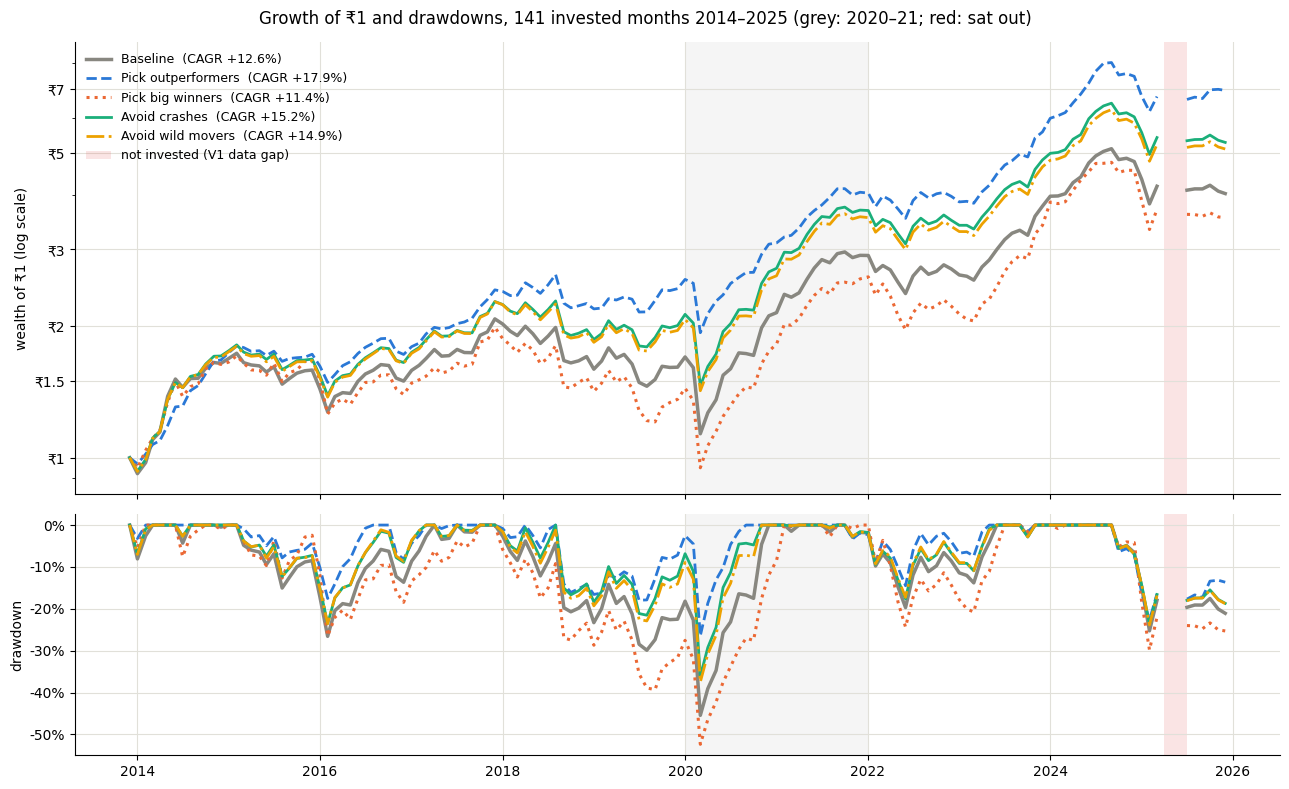

In [14]:
EXPORT_DIR = SANDBOX_DIR / "viz_exports_phase3a_portfolios_v2"; EXPORT_DIR.mkdir(parents=True, exist_ok=True)
_n = {"k": 0}
def save_fig(fig, name):
    _n["k"] += 1; p = EXPORT_DIR / f"{_n['k']:02d}_{name}.png"
    fig.savefig(p, dpi=130, bbox_inches="tight"); print(f"  [saved: {p.name}]")
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,
                     "grid.color":"#e1e0d9","grid.linewidth":0.8})
STY = {"Baseline":dict(color="#888780",ls="-",lw=2.5),
       "Pick outperformers":dict(color="#2a78d6",ls="--",lw=2),
       "Pick big winners":dict(color="#eb6834",ls=":",lw=2.2),
       "Avoid crashes":dict(color="#1baf7a",ls="-",lw=2),
       "Avoid wild movers":dict(color="#eda100",ls="-.",lw=2)}
idx = [R.index[0] - pd.offsets.MonthBegin(1)] + list(R.index)
def shade(ax, label=False):
    ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2021-12-31"), color="#888780", alpha=0.08, lw=0)
    if SIT_OUT:
        ax.axvspan(pd.Period(SIT_OUT[0], "M").start_time, pd.Period(SIT_OUT[-1], "M").end_time,
                   color="#e24b4a", alpha=0.15, lw=0, label="not invested (V1 data gap)" if label else None)
# Break the lines across sat-out months (NaN) instead of drawing a straight line through them.
GAP_X = [pd.Period(m, "M").start_time for m in SIT_OUT]
def with_breaks(values):
    s = pd.concat([pd.Series(values, index=idx), pd.Series(np.nan, index=GAP_X)]).sort_index()
    return s.index, s.to_numpy()

from matplotlib.ticker import FuncFormatter, LogLocator
fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios":[3,1.6]})
for p in PORTFOLIOS:
    w = wealth_curve(R[p])
    a1.plot(*with_breaks(w), label=f"{p}  (CAGR {T.loc[p,'cagr']:+.1%})", **STY[p])
    a2.plot(*with_breaks(w / np.maximum.accumulate(w) - 1), **STY[p])
a1.set_yscale("log"); a1.set_ylabel("wealth of ₹1 (log scale)")
a1.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 1.5, 2, 3, 5, 7)))
a1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"₹{v:.2f}".rstrip("0").rstrip(".")))
a1.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
shade(a1, label=True); shade(a2)
a1.legend(frameon=False, fontsize=9)
a2.set_ylabel("drawdown"); a2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle(f"Growth of ₹1 and drawdowns, {len(R)} invested months {R.index[0].year}–{R.index[-1].year} "
             "(grey: 2020–21; red: sat out)")
fig.tight_layout(); save_fig(fig, "wealth_and_drawdown"); plt.show()

  [saved: 02_risk_vs_return.png]


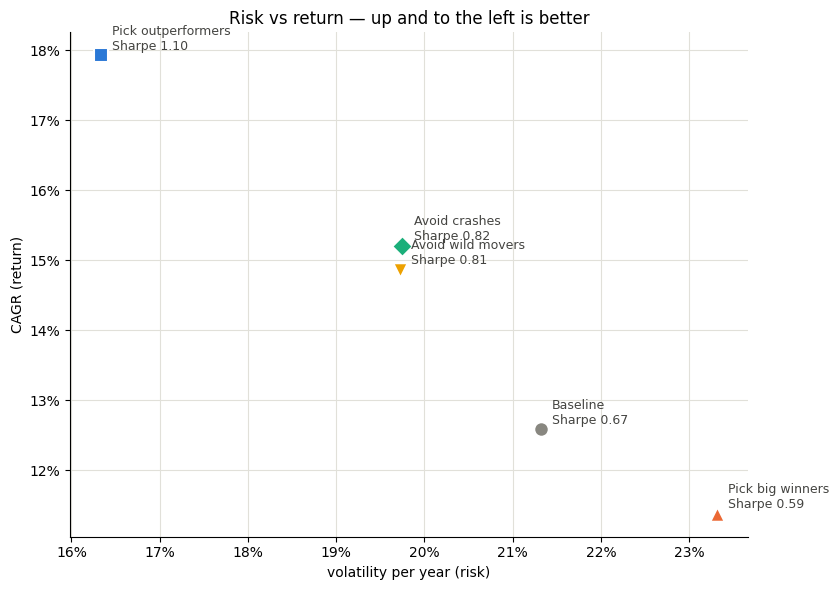

In [15]:
fig, ax = plt.subplots(figsize=(8.5, 6))
MK = {"Baseline":"o","Pick outperformers":"s","Pick big winners":"^","Avoid crashes":"D","Avoid wild movers":"v"}
for p in PORTFOLIOS:
    ax.scatter(T.loc[p,"vol"], T.loc[p,"cagr"], s=110, color=STY[p]["color"], marker=MK[p],
               edgecolor="white", linewidth=1.5, zorder=3)
    ax.annotate(f"{p}\nSharpe {T.loc[p,'sharpe']:.2f}", (T.loc[p,"vol"], T.loc[p,"cagr"]),
                xytext=(8, 4), textcoords="offset points", fontsize=9, color="#444441")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("volatility per year (risk)"); ax.set_ylabel("CAGR (return)")
ax.set_title("Risk vs return — up and to the left is better")
fig.tight_layout(); save_fig(fig, "risk_vs_return"); plt.show()

  [saved: 03_active_by_year.png]


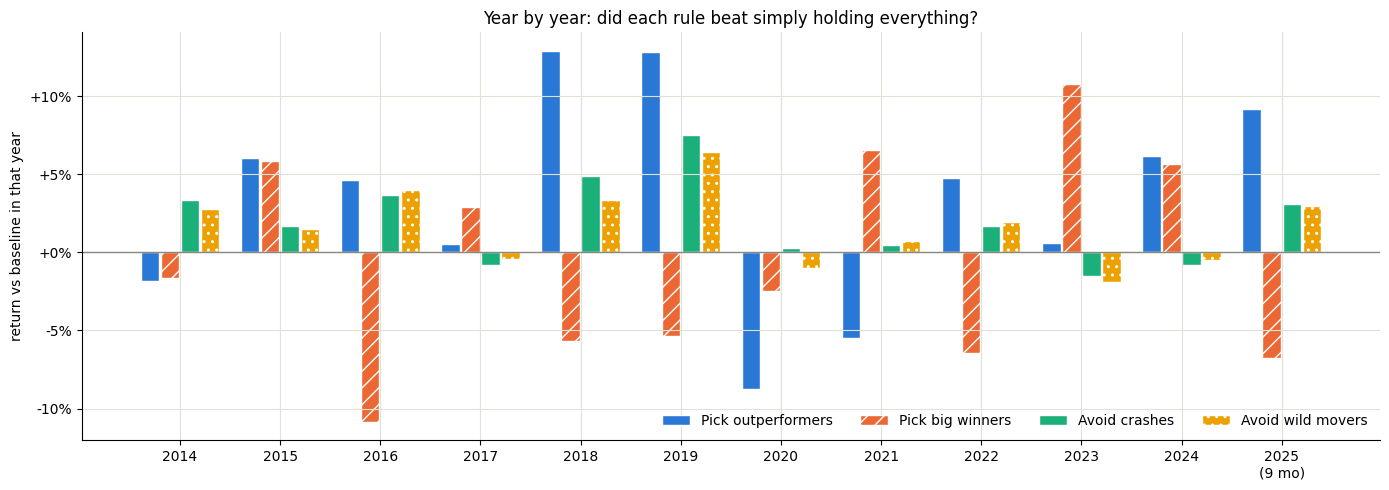

In [16]:
yrs = sorted(R.index.year.unique()); xs = np.arange(len(yrs)); bw = 0.2
months_in = R.groupby(R.index.year).size()
fig, ax = plt.subplots(figsize=(14, 5))
for k, p in enumerate(list(PORTFOLIOS)[1:]):
    act = (R[p] - R["Baseline"]).groupby(R.index.year).apply(lambda a: (1 + a).prod() - 1)
    ax.bar(xs + (k - 1.5) * bw, act.reindex(yrs), bw * 0.92, color=STY[p]["color"], label=p,
           hatch=["", "//", "", ".."][k], edgecolor="white")
ax.axhline(0, color="#888780", lw=1)
ax.set_xticks(xs)
ax.set_xticklabels([f"{y}" if months_in[y] == 12 else f"{y}\n({months_in[y]} mo)" for y in yrs])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_ylabel("return vs baseline in that year"); ax.legend(frameon=False, ncol=4)
ax.set_title("Year by year: did each rule beat simply holding everything?")
fig.tight_layout(); save_fig(fig, "active_by_year"); plt.show()

  [saved: 04_held_vs_set_aside.png]


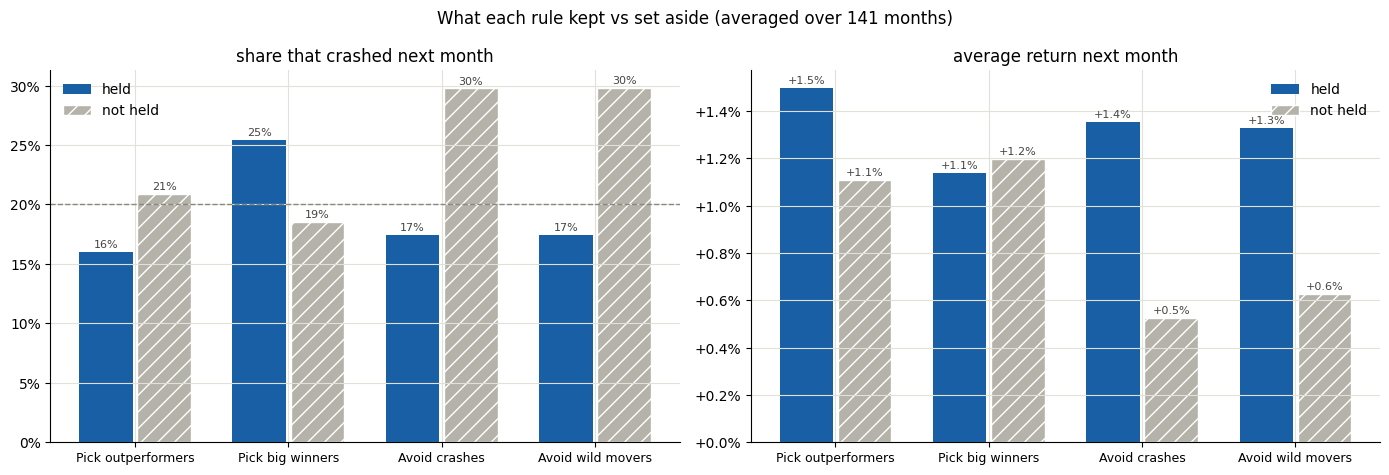

In [17]:
# What did each rule hold vs set aside?  Crash rate and average return, two groups per portfolio
D = diag.groupby("portfolio")[["crash_held","crash_other","ret_held","ret_other"]].mean().reindex(list(PORTFOLIOS)[1:])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8))
xs = np.arange(len(D)); bw = 0.38
for ax, (h, o, lab, fmt) in zip((a1, a2), [("crash_held","crash_other","share that crashed next month","{:.0%}"),
                                            ("ret_held","ret_other","average return next month","{:+.1%}")]):
    b1 = ax.bar(xs - bw/2, D[h], bw*0.92, color="#185fa5", label="held")
    b2 = ax.bar(xs + bw/2, D[o], bw*0.92, color="#b4b2a9", label="not held", hatch="//", edgecolor="white")
    for bars in (b1, b2):
        for bx in bars:
            v = bx.get_height(); ax.annotate(fmt.format(v), (bx.get_x()+bx.get_width()/2, v),
                xytext=(0, 3 if v >= 0 else -12), textcoords="offset points", ha="center", fontsize=8, color="#444441")
    ax.set_xticks(xs); ax.set_xticklabels(D.index, fontsize=9); ax.set_title(lab); ax.legend(frameon=False)
    if "crash" in h: ax.axhline(0.2, color="#888780", ls="--", lw=1)
a2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.1%}"))
a1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle(f"What each rule kept vs set aside (averaged over {len(R)} months)")
fig.tight_layout(); save_fig(fig, "held_vs_set_aside"); plt.show()

In [18]:
# DIAGNOSTIC: are the "good" portfolios all the same low-volatility tilt?
tilt = snap.merge(df[["date","ticker"] + Z], on=["date","ticker"], how="left")
assert tilt[Z].notna().all().all(), "missing features for held stocks"

rows = []
for p in PORTFOLIOS:
    per_month = []
    for d, held in holds[p].items():
        day = tilt[tilt["date"] == d]
        per_month.append(day.loc[day["ticker"].isin(held), Z].mean())
    rows.append(pd.DataFrame(per_month).mean().rename(p))
print("1. average feature z-score of HELD stocks (0 = market average; negative vol = calmer stocks):")
print(pd.DataFrame(rows).round(2).to_string())

ov = []
for d in sorted(holds["Baseline"]):
    allt = holds["Baseline"][d]
    out_c = allt - holds["Avoid crashes"][d]
    out_v = allt - holds["Avoid wild movers"][d]
    ov.append(len(out_c & out_v) / len(out_c))
print(f"\n2. of the stocks 'Avoid crashes' sets aside, share also set aside by 'Avoid wild movers': "
      f"mean {np.mean(ov):.1%}, min {np.min(ov):.1%}")

PC = ["p_outperform","p_top","p_crash","p_highvol"]
C = snap.groupby("date")[PC].corr(method="spearman").groupby(level=1).mean().reindex(index=PC, columns=PC)
print("\n3. rank correlation between the four predictions (average across months):")
print(C.round(2).to_string())

print("\n4. stricter CIs for 4 portfolios tested at once (98.75% instead of 95%):")
for p, bt in BT.items():
    a = np.percentile(bt["active"], [0.625, 99.375]); s = np.percentile(bt["sharpe_diff"], [0.625, 99.375])
    print(f"   {p:<20} active [{a[0]:+.2%}, {a[1]:+.2%}]   Sharpe diff [{s[0]:+.3f}, {s[1]:+.3f}]")

1. average feature z-score of HELD stocks (0 = market average; negative vol = calmer stocks):
                    momentum_12_1_z  reversal_1m_z  realized_vol_60_z  log_turnover_z  overnight_drift_z
Baseline                       0.00          -0.00              -0.00           -0.00              -0.00
Pick outperformers             0.83          -0.01              -0.64            0.19              -0.39
Pick big winners               0.96           0.07               1.07            0.11               0.13
Avoid crashes                  0.06          -0.04              -0.36           -0.02              -0.11
Avoid wild movers             -0.00          -0.02              -0.37            0.01              -0.10

2. of the stocks 'Avoid crashes' sets aside, share also set aside by 'Avoid wild movers': mean 86.2%, min 73.7%

3. rank correlation between the four predictions (average across months):
              p_outperform  p_top  p_crash  p_highvol
p_outperform          1.00  -0.04 

## Cell 12 — Copy-paste summary

In [19]:
print("=" * 78); print("SAVED FIGURES:", EXPORT_DIR)
for p in sorted(EXPORT_DIR.glob("*.png")): print("   ", p.name)
print("=" * 78); print("COPY BELOW THIS LINE AND PASTE BACK"); print("=" * 78)
print(f"\n[data gap] V1 has no cards {HOLE_LO.date()} -> {HOLE_HI.date()} ({HOLE_DAYS} trading days); "
      f"short runs: {len(RUNS) - 1}, unexplained: {n_unexpl}")
print(f"[gap cause] blank builder inputs: {blank_cols if blank_cols else 'NONE FOUND'}")
for c, sh in AUDIT_B.items():
    print(f"    {c:<18} " + "  ".join(f"{k}: {v:.1%}" for k, v in sh.items()))
print(f"[plan] invested {len(reb)} months, sat out {SIT_OUT}; late entries: "
      f"{PLAN.loc[PLAN['invest'] & (PLAN['delay'] > 0), 'month'].tolist()}")
print(f"[holding] adjacent-month overlap mean {adj['overlap'].mean():.2f} max {adj['overlap'].max()}; "
      f"uncovered mean {adj['uncovered'].mean():.2f} max {adj['uncovered'].max()}")
print(f"[coverage] median {per.median():.0f} stocks/month (min {per.min()}); usable {complete.mean():.2%} of cards")
print(f"[audit] " + "; ".join(f"{k}: {v}" for k, v in AUDIT.items()))
print(f"[missing-return check] data-ends stock-months {len(ends)} = {len(ends)/len(inidx)*100:.3f}%"
      + (f", median return to last price {ends['partial_ret'].median():+.3f}" if len(ends) else "")
      + f"  -> {'MATERIAL' if MATERIAL else 'small'}")
print("\n[performance]  (invested months only)")
print(T[["cagr","vol","sharpe","max_dd","hit_months","turnover","cagr_2014_19","cagr_2020_25","ret_2020_21"]]
      .to_string(float_format=lambda x: f"{x:+.3f}"))
print("\n[vs baseline]")
print(T.loc[list(PORTFOLIOS)[1:], ["active","active_lo","active_hi","active_2014_19","active_2020_25",
      "vol_diff_lo","vol_diff_hi","sharpe_diff_lo","sharpe_diff_hi"]].to_string(float_format=lambda x: f"{x:+.4f}"))
print("\n[verdicts]")
for p, v in VERDICT.items(): print(f"  {p:<20} {v}")
print("\n[held vs set aside, monthly averages]")
print(D.to_string(float_format=lambda x: f"{x:+.4f}"))
print("=" * 78)

SAVED FIGURES: /content/drive/MyDrive/moonshot_ml_sandbox/viz_exports_phase3a_portfolios_v2
    01_wealth_and_drawdown.png
    02_risk_vs_return.png
    03_active_by_year.png
    04_held_vs_set_aside.png
COPY BELOW THIS LINE AND PASTE BACK

[data gap] V1 has no cards 2025-03-17 -> 2025-06-17 (62 trading days); short runs: 1, unexplained: 0
[gap cause] blank builder inputs: ['realized_vol_60']
    daily_return       before (60d): 0.0%  inside hole: 3.2%  after (60d): 0.0%
    overnight_return   before (60d): 0.0%  inside hole: 3.2%  after (60d): 0.0%
    realized_vol_60    before (60d): 0.3%  inside hole: 97.4%  after (60d): 0.4%
    turnover           before (60d): 0.0%  inside hole: 1.6%  after (60d): 0.0%
    Open               before (60d): 0.0%  inside hole: 1.6%  after (60d): 0.0%
[plan] invested 141 months, sat out ['2025-04', '2025-05', '2025-06']; late entries: []
[holding] adjacent-month overlap mean 0.29 max 3; uncovered mean 0.88 max 3
[coverage] median 490 stocks/month (min

## Reading order
1. Cell 4 reproduction check, Cell 5 diagnosis, Cell 6 plan, Cell 8 audit — all `[PASS]`.
2. Cell 9 verdict on hidden disasters.
3. Risk-vs-return chart: who moved up-and-left of baseline?
4. Rule verdicts in Cell 10.
5. Year-by-year chart: was any edge concentrated in a few years? What happened in 2020–21?
6. Held vs set-aside chart: did "avoid" rules actually set aside the crashers — and what returns did they give up?

**Boundary:** no trading costs; turnover shows how much they would matter. 2025 has 9 invested months.